# Image Colorization — ResNet18-U-Net with Scheduler

В предыдущем эксперименте использовали U-Net с предобученным **ResNet18 encoder**. Веса encoder были заморожены, обучался только decoder. Это позволило снизить L1 по сравнению с обычной U-Net, но после нескольких эпох validation loss начал колебаться.

Теперь попробуем добавить **ReduceLROnPlateau**. Он уменьшает learning rate, если validation loss некоторое время не улучшается. Проверим, поможет ли это стабилизировать обучение и получить более низкую ошибку.

**Что не меняем:** ResNet18 encoder, заморозку весов, decoder, датасет и L1 Loss. **Что меняем:** scheduler и число эпох (40). Поэтому сравнение не изолирует влияние scheduler от продолжительности обучения.

## 1. Setup


In [ ]:
import random
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
import wandb
from torch import nn
from skimage.color import lab2rgb

from image_colorization.resnet_unet import ResNetUNet
from image_colorization.dataloaders import create_dataloaders
from image_colorization.training import train_model
from image_colorization.color_utils import denormalize_lab

## 2. Experiment Configuration

In [ ]:
NUM_EPOCHS = 40
BATCH_SIZE = 32
LEARNING_RATE = 1e-3
SEED = 101

SCHEDULER_FACTOR = 0.5
SCHEDULER_PATIENCE = 3
MIN_LR = 1e-5

experiment_name = "resnet18_unet_frozen_scheduler"

config = {
    "architecture": "resnet18_unet",
    "encoder": "ResNet18",
    "pretrained": True,
    "encoder_frozen": True,
    "num_epochs": NUM_EPOCHS,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "optimizer": "AdamW",
    "loss": "L1",
    "scheduler": "ReduceLROnPlateau",
    "scheduler_mode": "min",
    "scheduler_factor": SCHEDULER_FACTOR,
    "scheduler_patience": SCHEDULER_PATIENCE,
    "scheduler_min_lr": MIN_LR
}

## 3. Data Paths and Checkpoints

In [ ]:
images_dir = Path("VOCdevkit/VOC2012/JPEGImages")
train_path = Path("data/splits/train.txt")
val_path = Path("data/splits/val.txt")

checkpoint_dir = Path("/content/drive/MyDrive/image-colorization/checkpoints")
checkpoint_dir.mkdir(parents=True, exist_ok=True)

last_path = checkpoint_dir / f"{experiment_name}_last.pt"
best_path = checkpoint_dir / f"{experiment_name}_best.pt"

## 4. DataLoaders

In [ ]:
train_loader, val_loader = create_dataloaders(
    images_dir=images_dir,
    train_path=train_path,
    val_path=val_path,
    batch_size=BATCH_SIZE,
)

## 5. Model, Optimizer, and Scheduler

**ReduceLROnPlateau** отслеживает `val_loss` и уменьшает learning rate в `factor` раз, если метрика не улучшается `patience` эпох. В `training.py` после валидации нужно вызывать `scheduler.step(val_loss[-1])`.

В этом ноутбуке предполагается, что ты добавила в `train_model()` необязательный аргумент **`scheduler=None`** и передаёшь туда созданный scheduler.

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

model = ResNetUNet().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)
criterion = nn.L1Loss()

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=SCHEDULER_FACTOR,
    patience=SCHEDULER_PATIENCE,
    min_lr=MIN_LR,
)

Device: cuda
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 175MB/s]


## 6. Weights & Biases

In [ ]:
wandb.login()

run = wandb.init(
    entity="arzushkaB",
    project="image-colorization",
    name=experiment_name,
    config=config,
)

## 7. Model Training

Эксперимент начинается **с новой инициализации decoder**, а не продолжает старый checkpoint. `best.pt` и `last.pt` сохраняются под отдельными именами, не перезаписывая предыдущий эксперимент.

**Важно:** в `training.py` должен быть аргумент `scheduler`. После вычисления `val_loss` вызывай `scheduler.step(val_loss[-1])` и при желании логируй `optimizer.param_groups[0]["lr"]` в W&B.

In [ ]:
train_losses, val_losses = train_model(
    model=model,
    criterion=criterion,
    optimizer=optimizer,
    train_loader=train_loader,
    val_loader=val_loader,
    num_epochs=NUM_EPOCHS,
    device=device,
    last_path=last_path,
    best_path=best_path,
    run=run,
    scheduler=scheduler,
)

print(f"Train L1: {train_losses[-1]:.5f}")
print(f"Val L1: {val_losses[-1]:.5f}")
print(f"Best Val L1: {min(val_losses):.5f} (epoch {np.argmin(val_losses) + 1})")

run.finish()

## 8. Checkpoint Verification

После первой эпохи файлы появятся на Google Drive. После завершения обучения проверяем, какие эпохи сохранились.

In [ ]:
for name, path in (("best", best_path), ("last", last_path)):
    print(f"{name}: {path.exists()} — {path}")
    if path.exists():
        checkpoint = torch.load(path, map_location="cpu", weights_only=True)
        print("Epoch:", checkpoint["epoch"])
        print("Val L1:", checkpoint["val_losses"][-1])

best: True — /content/drive/MyDrive/image-colorization/checkpoints/resnet18_unet_frozen_scheduler_best.pt
Epoch: 7
Val L1: 0.06050483793246463
last: True — /content/drive/MyDrive/image-colorization/checkpoints/resnet18_unet_frozen_scheduler_last.pt
Epoch: 40
Val L1: 0.06314966942043376


## 9. Training Curves

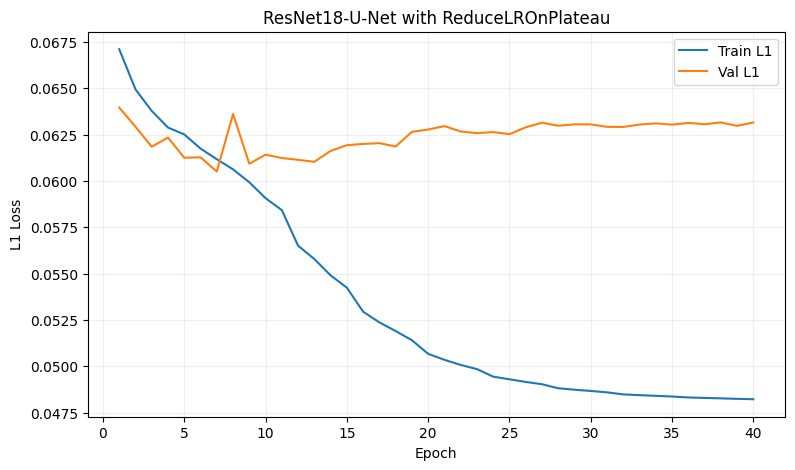

In [ ]:
epochs = np.arange(1, len(train_losses) + 1)

plt.figure(figsize=(9, 5))
plt.plot(epochs, train_losses, label="Train L1")
plt.plot(epochs, val_losses, label="Val L1")
plt.xlabel("Epoch")
plt.ylabel("L1 Loss")
plt.title("ResNet18-U-Net with ReduceLROnPlateau")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## 10. Best Model Evaluation

Берём `best.pt` и показываем одни и те же изображения из `val_loader` (`shuffle=False`), чтобы сравнение с предыдущими экспериментами было корректным.

In [ ]:
best_checkpoint = torch.load(best_path, map_location=device, weights_only=True)
model.load_state_dict(best_checkpoint["model_state_dict"])
model.eval()

L, ab = next(iter(val_loader))
with torch.no_grad():
    pred_ab = model(L.to(device)).cpu()

print("Best epoch:", best_checkpoint["epoch"])
print("Gray baseline L1:", criterion(torch.zeros_like(ab), ab).item())
print("ResNet18-U-Net L1:", criterion(pred_ab, ab).item())

Best epoch: 7
Gray baseline L1: 0.06412637233734131
ResNet18-U-Net L1: 0.060799770057201385


## 11. Prediction Visualization




In [ ]:
n_images = 32
fig, axes = plt.subplots(n_images, 3, figsize=(10, n_images * 3.2))

for i in range(n_images):
    l_np = L[i, 0].numpy()
    ab_np = ab[i].permute(1, 2, 0).numpy()
    pred_np = pred_ab[i].permute(1, 2, 0).numpy()

    original = lab2rgb(denormalize_lab(l_np, ab_np))
    grayscale = np.repeat(l_np[..., None], 3, axis=2)
    colorized = lab2rgb(denormalize_lab(l_np, pred_np))

    for ax, img, title in zip(
        axes[i],
        (original, grayscale, colorized),
        ("Original", "Grayscale", "ResNet18-U-Net + scheduler"),
    ):
        ax.imshow(np.clip(img, 0, 1))
        ax.set_title(title)
        ax.axis("off")

plt.tight_layout()
plt.show()

### Results and Conclusions

В этом эксперименте использовали `ReduceLROnPlateau` для изменения learning rate в процессе обучения ResNet18-U-Net. Модель обучалась 40 эпох, encoder оставался замороженным.

По графикам видно, что training loss продолжала снижаться на протяжении всего обучения, однако validation loss достигла минимума на 7-й эпохе и в дальнейшем начала расти. Это указывает на признаки переобучения.

Для лучшего checkpoint получили следующие результаты на validation-батче:

- **Grayscale baseline L1:** 0.06413
- **ResNet18-U-Net L1:** 0.06080

По сравнению с предыдущим экспериментом без scheduler улучшения validation loss не получили. Визуальное качество колоризации также оказалось хуже: изображения по-прежнему имеют недостаточно насыщенные цвета.

Таким образом, увеличение количества эпох и использование `ReduceLROnPlateau` в данном запуске не привели к улучшению качества модели. При этом нельзя однозначно утверждать, что ухудшение вызвано самим scheduler, поскольку эксперименты проводились с разной случайной инициализацией.